# 01 - Exploração do UCDDB

Aqui a gente olha os arquivos do dataset antes de escrever o `ai/load_ucddb.py`.

Quatro perguntas:
1. O que tem no `.rec`? (canais, frequência, horário de início)
2. Como é o `_respevt.txt`? (colunas, formato, tipos de evento)
3. O que tem na `SubjectDetails.xls`? (onde está o AHI)
4. Os horários dos eventos batem com o início da gravação?

Antes de rodar: os dados precisam estar em `data/raw/ucddb-1.0.0/files/` (ver `data/README.md`).

In [1]:
from pathlib import Path
import collections

import numpy as np
import pandas as pd
import pyedflib
import matplotlib.pyplot as plt

# pasta raiz do repo (funciona rodando de dentro de notebooks/ ou da raiz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# pasta onde ficam os arquivos do ucddb
DATA = ROOT / "data" / "raw" / "ucddb-1.0.0" / "files"
assert DATA.exists(), f"não achei a pasta de dados: {DATA}"

# lista dos sujeitos, pegando do arquivo RECORDS que vem no dataset
SUBJECTS = [line.strip()[5:8] for line in (DATA / "RECORDS").read_text().splitlines()
            if line.strip().endswith(".rec")]
print(len(SUBJECTS), "sujeitos:", SUBJECTS)

25 sujeitos: ['002', '003', '005', '006', '007', '008', '009', '010', '011', '012', '013', '014', '015', '017', '018', '019', '020', '021', '022', '023', '024', '025', '026', '027', '028']


## Pergunta 1 - O que tem no `.rec`?

O `.rec` é um arquivo EDF com outra extensão, o `pyedflib` abre ele direto.

In [2]:
# sujeito que a gente vai olhar primeiro
SID = "002"

# abre o arquivo da gravação
f = pyedflib.EdfReader(str(DATA / f"ucddb{SID}.rec"))

# tabela com os canais: nome, frequência, quantidade de amostras e unidade
channels = pd.DataFrame({
    "label": f.getSignalLabels(),
    "fs_hz": f.getSampleFrequencies(),
    "n_samples": f.getNSamples(),
    "unit": [f.getPhysicalDimension(i) for i in range(f.signals_in_file)],
})

# horário que a gravação começou e quanto tempo durou
start = f.getStartdatetime()
duration_s = f.getFileDuration()
print("início da gravação:", start, "| duração:", duration_s, "s =", round(duration_s / 3600, 2), "h")
print("obs: a data é falsa (anonimizada), só o horário é real")
channels

início da gravação: 2002-01-01 00:11:04 | duração: 22470.0 s = 6.24 h
obs: a data é falsa (anonimizada), só o horário é real


,label,fs_hz,n_samples,unit
0,Lefteye,64.0,1438080,NV
1,RightEye,64.0,1438080,NV
2,EMG,64.0,1438080,NV
3,C3A2,128.0,2876160,NV
4,C4A1,128.0,2876160,NV
5,ECG,128.0,2876160,NV
6,SpO2,8.0,179760,%
7,Sound,8.0,179760,
8,Flow,8.0,179760,L/min
9,Sum,8.0,179760,


In [3]:
# acha o canal de SpO2 pelo nome (melhor que confiar no índice)
i_spo2 = f.getSignalLabels().index("SpO2")

# frequência do canal (amostras por segundo)
fs = f.getSampleFrequency(i_spo2)

# variável pra guardar o sinal de SpO2 da noite inteira
spo2 = f.readSignal(i_spo2)
f.close()

print(f"SpO2: índice {i_spo2}, {fs} Hz, {len(spo2)} amostras")
print("primeiras amostras:", np.round(spo2[:8], 2), "-> o sensor ainda não estava no dedo")
print("mín / máx / média:", round(spo2.min(), 2), "/", round(spo2.max(), 2), "/", round(spo2.mean(), 2))
print("% das amostras abaixo de 50% (sensor solto ou desligado):", round((spo2 < 50).mean() * 100, 2))
print("os valores não são inteiros (o EDF converte de digital pra físico):", np.round(spo2[1000:1005], 3))

SpO2: índice 6, 8.0 Hz, 179760 amostras
primeiras amostras: [3.88 3.91 3.88 3.86 3.88 3.88 3.88 3.91] -> o sensor ainda não estava no dedo
mín / máx / média: 3.77 / 98.07 / 93.67
% das amostras abaixo de 50% (sensor solto ou desligado): 0.16
os valores não são inteiros (o EDF converte de digital pra físico): [92.168 92.12  92.12  92.12  92.097]


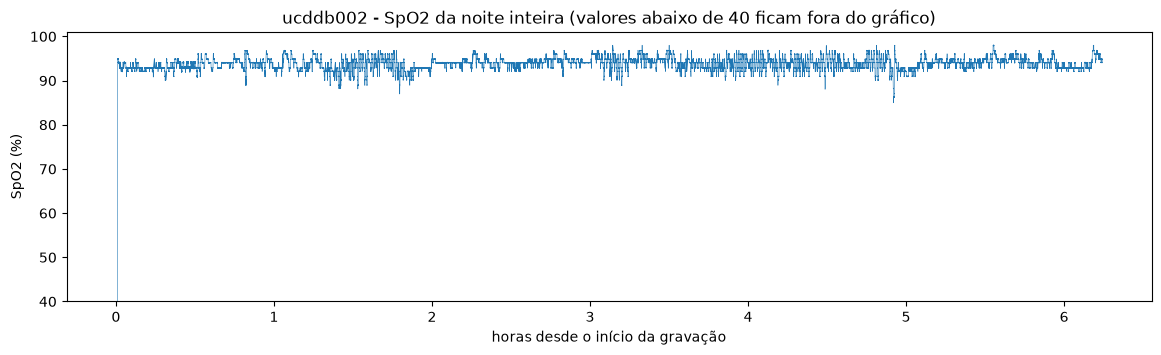

In [4]:
# eixo do tempo em horas desde o início
t_h = np.arange(len(spo2)) / fs / 3600

# gráfico da SpO2 da noite inteira
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(t_h, spo2, lw=0.4)
ax.set_ylim(40, 101)
ax.set_xlabel("horas desde o início da gravação")
ax.set_ylabel("SpO2 (%)")
ax.set_title(f"ucddb{SID} - SpO2 da noite inteira (valores abaixo de 40 ficam fora do gráfico)")
plt.show()

In [5]:
# resumo de todos os sujeitos: início, duração e quanto do sinal é inválido (< 50%)
rows = []
for sid in SUBJECTS:
    f = pyedflib.EdfReader(str(DATA / f"ucddb{sid}.rec"))
    i = f.getSignalLabels().index("SpO2")
    x = f.readSignal(i)
    rows.append({
        "subject": sid,
        "start": f.getStartdatetime().strftime("%H:%M:%S"),
        "duration_h": round(f.getFileDuration() / 3600, 2),
        "fs_spo2": f.getSampleFrequency(i),
        "pct_below_50": round((x < 50).mean() * 100, 2),
        "min_valid": round(x[x >= 50].min(), 1),
        "max": round(x.max(), 1),
    })
    f.close()

# tabela pra comparar os sujeitos
recs = pd.DataFrame(rows)
recs

,subject,start,duration_h,fs_spo2,pct_below_50,min_valid,max
0,002,00:11:04,6.24,8.0,0.16,85.0,98.1
1,003,23:07:50,7.36,8.0,0.07,51.4,97.9
2,005,23:28:42,6.89,8.0,0.65,78.4,100.1
3,006,23:57:14,6.74,8.0,2.66,63.2,95.0
4,007,23:30:22,6.78,8.0,0.01,84.3,97.0
5,008,23:29:11,6.40,8.0,4.83,86.8,96.1
6,009,22:35:22,7.71,8.0,0.00,71.4,96.9
7,010,22:51:18,7.56,8.0,0.02,68.0,97.9
8,011,22:47:38,7.51,8.0,0.05,58.7,97.9
9,012,23:23:21,7.21,8.0,8.12,55.1,97.9


**Respostas da pergunta 1**
- São 14 canais, iguais em todos os sujeitos. A SpO2 é o canal `"SpO2"`, a 8 Hz, em %. Tem também o `"Pulse"` a 8 Hz.
- O horário de início vem no cabeçalho do EDF. A data é anonimizada.
- Todo sujeito tem trechos abaixo de 50% (sensor solto). Isso justifica o portão de qualidade.
- Tem valor um pouco acima de 100 (tipo 100,2), então o limite de cima do portão precisa de uma folga.

## Pergunta 2 - Como é o `_respevt.txt`?

In [6]:
# lê o arquivo de eventos como texto puro pra ver o formato
raw = (DATA / f"ucddb{SID}_respevt.txt").read_text(encoding="latin-1").splitlines()

# mostra as primeiras linhas do jeito que estão no arquivo
for line in raw[:6]:
    print(repr(line))

'                              Respiratory Event List'
'        Respiratory Event           Desaturation   Snore Arousal     B/T'
' Time       Type   PB/CS  Duration  Low    %Drop                 Rate  Change'
'00:29:13  HYP-C             16       89.9    4.1     -     -      64.7   -5.7 '
'00:59:46  HYP-C             20       92      2.1     -     -      85.2   -26.2'
'01:01:37  HYP-C             13       92.8    4.1     -     -              '


In [7]:
# teste pra ver por que o split() não funciona aqui:
# quando uma coluna está vazia ela some e o número de pedaços muda
examples = [l for l in raw[3:] if l.strip()][:40]
print(collections.Counter(len(l.split()) for l in examples))

# mostra uma linha que veio com só 5 pedaços
for l in examples:
    if len(l.split()) == 5:
        print("linha com 5 pedaços:", repr(l))
        break

Counter({9: 30, 7: 9, 5: 1})
linha com 5 pedaços: '01:02:25  HYP-C             13                       -     -              '


In [8]:
# nomes das colunas que a gente vai usar
EVENT_COLS = ["time", "type", "pb_cs", "duration_s", "spo2_low", "spo2_drop_pct", "snore", "arousal"]

# posição (início, fim) de cada coluna na linha
# as colunas B/T (frequência cardíaca) ficam de fora: elas desalinham quando o valor passa de 100
# e a gente não usa elas no projeto
EVENT_COLSPECS = [(0, 8), (10, 18), (18, 24), (24, 33), (33, 41), (41, 49), (49, 55), (55, 61)]

# função pra ler os eventos de um sujeito
def read_events_raw(sid):
    # lê o arquivo por largura fixa, pulando as 3 linhas de cabeçalho
    d = pd.read_fwf(DATA / f"ucddb{sid}_respevt.txt", colspecs=EVENT_COLSPECS, names=EVENT_COLS,
                    skiprows=3, encoding="latin-1", dtype=str)

    # fica só com as linhas que começam com um horário (hh:mm:ss)
    d = d[d["time"].str.match(r"^\d\d:\d\d:\d\d$", na=False)].copy()

    # transforma as colunas numéricas em número
    for c in ["duration_s", "spo2_low", "spo2_drop_pct"]:
        d[c] = pd.to_numeric(d[c])

    # coluna pra saber de qual sujeito é cada evento
    d.insert(0, "subject", sid)
    return d.reset_index(drop=True)

# eventos da noite 002
ev002 = read_events_raw(SID)
print(len(ev002), "eventos na noite", SID)
ev002.head(10)

124 eventos na noite 002


,subject,time,type,pb_cs,duration_s,spo2_low,spo2_drop_pct,snore,arousal
0,002,00:29:13,HYP-C,NaN,16,89.9,4.1,-,-
1,002,00:59:46,HYP-C,NaN,20,92.0,2.1,-,-
2,002,01:01:37,HYP-C,NaN,13,92.8,4.1,-,-
3,002,01:02:25,HYP-C,NaN,13,NaN,NaN,-,-
4,002,01:07:47,HYP-C,NaN,14,90.8,4.1,-,+
5,002,01:11:37,HYP-C,NaN,10,90.8,3.2,-,+
6,002,01:29:42,HYP-C,NaN,15,90.8,5.3,-,-
7,002,01:31:52,HYP-C,NaN,13,88.7,5.3,-,+
8,002,01:34:24,HYP-C,NaN,14,89.9,4.1,-,-
9,002,01:35:47,HYP-O,NaN,22,88.1,5.9,-,+


In [9]:
# junta os eventos de todos os sujeitos numa tabela só
events = pd.concat([read_events_raw(s) for s in SUBJECTS], ignore_index=True)
print("total de linhas de evento:", len(events))
print(events["type"].value_counts())
print()

# quantos eventos não têm dessaturação marcada (Low vazio)
print("eventos sem dessaturação marcada:", events["spo2_low"].isna().sum())

# contagem só de apneias e hipopneias, e com os POSSIBLE junto
apnea_hyp = events["type"].str.startswith(("APNEA", "HYP"))
print("apneias + hipopneias:", apnea_hyp.sum(), "| com POSSIBLE:", (apnea_hyp | (events["type"] == "POSSIBLE")).sum())

total de linhas de evento: 3428
type
HYP-O       1433
HYP-C       1076
APNEA-C      343
APNEA-O      216
APNEA-M      136
HYP-M        114
PB EVENT      91
POSSIBLE      19
Name: count, dtype: int64

eventos sem dessaturação marcada: 266
apneias + hipopneias: 3318 | com POSSIBLE: 3337


**Respostas da pergunta 2**
- Tem 3 linhas de cabeçalho e depois uma linha por evento, em largura fixa (dá pra ler com `read_fwf` e `colspecs`).
- Colunas: horário, tipo, PB/CS, duração (s), SpO2 mínima (`Low`), queda (`%Drop`), ronco, despertar e frequência cardíaca (B/T).
- Tipos: `HYP-O`, `HYP-C`, `APNEA-C`, `APNEA-O`, `APNEA-M`, `HYP-M`, `PB EVENT` (respiração periódica) e `POSSIBLE`.
- A gente precisa decidir quais tipos entram no rótulo. Sugestão: só apneias e hipopneias (sem `PB EVENT` e sem `POSSIBLE`).
- Uma parte dos eventos não tem dessaturação marcada, então a oximetria não enxerga eles. Isso vai pro relatório como limitação.

## Pergunta 3 - O que tem na `SubjectDetails.xls`?

In [10]:
# lê a planilha com os dados de cada sujeito (precisa do pacote xlrd)
details = pd.read_excel(DATA / "SubjectDetails.xls")
print(details.columns.tolist())
details

['S/No', 'Study Number', 'Height (cm)', 'Weight (kg)', 'Gender', 'PSG Start Time', 'PSG AHI', 'BMI', 'Age', 'Epworth Sleepiness Score', 'Study Duration (hr)', 'Sleep Efficiency (%)', 'Unnamed: 12', 'No of data blocks in EDF']


C:\Users\taimi\AppData\Local\Temp\ipykernel_40076\3255384246.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  details = pd.read_excel(DATA / "SubjectDetails.xls")


,S/No,Study Number,Height (cm),Weight (kg),Gender,PSG Start Time,PSG AHI,BMI,Age,Epworth Sleepiness Score,Study Duration (hr),Sleep Efficiency (%),Unnamed: 12,No of data blocks in EDF
0,1,UCDDB002,172,100.3,M,0:11:04,23,33.9,54,16,6.2,84,NaN,22470
1,2,UCDDB003,179,102.0,M,23:07:50,51,31.8,48,13,7.3,81,NaN,26478
2,3,UCDDB005,176,100.4,M,23:28:42,13,32.4,65,19,6.9,63,NaN,24798
3,4,UCDDB006,185,103.5,M,23:57:14,31,30.2,52,3,6.7,89,NaN,24267
4,5,UCDDB007,183,84.0,M,23:30:22,12,25.1,47,15,6.8,90,NaN,24405
5,6,UCDDB008,145,59.8,F,23:29:11,5,28.4,63,1,6.4,64,NaN,23041
6,7,UCDDB009,180,101.5,M,22:35:22,12,31.3,52,19,7.7,80,NaN,27759
7,8,UCDDB010,174,119.0,M,22:51:18,34,39.3,38,2,7.6,92,NaN,27211
8,9,UCDDB011,188,101.0,M,22:47:38,8,28.6,51,8,7.5,60,NaN,27030
9,10,UCDDB012,179,97.5,M,23:23:21,25,30.4,51,16,7.2,85,NaN,25941


In [11]:
# tabela só com o que importa pro rótulo
labels = details[["Study Number", "Gender", "Age", "BMI", "PSG AHI"]].copy()

# id do sujeito no mesmo formato dos arquivos (ex: "002")
labels["subject"] = labels["Study Number"].str[-3:]

# rótulo da noite: apneia moderada/grave se AHI >= 15
labels["osa_ahi15"] = labels["PSG AHI"] >= 15

print("AHI >= 15:", labels["osa_ahi15"].sum(), "de", len(labels), "-> prevalência", round(labels["osa_ahi15"].mean(), 2))
print("sujeitos positivos:", labels.loc[labels["osa_ahi15"], "subject"].tolist())
print()

# casos perto do corte de 15, que é onde a regra deve errar mais
print("casos de fronteira (AHI entre 12 e 18):")
labels[labels["PSG AHI"].between(12, 18)].sort_values("PSG AHI")

AHI >= 15: 14 de 25 -> prevalência 0.56
sujeitos positivos: ['002', '003', '006', '010', '012', '013', '014', '019', '020', '023', '024', '025', '027', '028']

casos de fronteira (AHI entre 12 e 18):


,Study Number,Gender,Age,BMI,PSG AHI,subject,osa_ahi15
4,UCDDB007,M,47,25.1,12,007,False
6,UCDDB009,M,52,31.3,12,009,False
13,UCDDB017,M,53,37.8,12,017,False
2,UCDDB005,M,65,32.4,13,005,False
17,UCDDB021,F,41,33.6,13,021,False
22,UCDDB026,M,49,27.4,14,026,False
16,UCDDB020,M,52,34.0,15,020,True
10,UCDDB013,F,62,34.2,16,013,True
15,UCDDB019,M,49,30.9,16,019,True


**Respostas da pergunta 3**
- O AHI está na coluna `PSG AHI` (número inteiro).
- 14 de 25 têm AHI >= 15 (prevalência 0,56), igual ao mid-term.
- Tem vários casos bem no corte (15, 16, 14, 13). É aí que a regra vai errar.

## Pergunta 4 - Os horários batem?

Os eventos vêm em horário de relógio, mas a gente precisa de segundos desde o início da gravação.
A maioria das gravações começa antes da meia-noite, então um evento às 00:30 vem depois de um início às 23:00.
A conta é: `(hora do evento - hora do início) mod 24h`.

In [12]:
# função pra transformar "hh:mm:ss" em segundos
def clock_to_seconds(hhmmss):
    h, m, s = map(int, hhmmss.split(":"))
    return h * 3600 + m * 60 + s

# função pra calcular quantos segundos depois do início cada evento começou
def add_onset_seconds(ev, start_hhmmss):
    ev = ev.copy()
    t0 = clock_to_seconds(start_hhmmss)
    # o mod 24h resolve a virada da meia-noite
    ev["onset_s"] = (ev["time"].map(clock_to_seconds) - t0) % 86400
    return ev

# horário de início da noite 002 (pega da tabela recs)
start_002 = recs.set_index("subject").loc[SID, "start"]

# eventos da 002 com o tempo em segundos
ev002 = add_onset_seconds(ev002, start_002)
print("início:", start_002, "| primeiro evento:", ev002["time"].iloc[0], "->", ev002["onset_s"].iloc[0], "s")
print("último evento:", ev002["time"].iloc[-1], "->", round(ev002["onset_s"].iloc[-1] / 3600, 2), "h depois do início")

print("\ngravações que começam antes da meia-noite:", (recs["start"] > "12:00:00").sum(), "de", len(recs))

início: 00:11:04 | primeiro evento: 00:29:13 -> 1089 s
último evento: 05:05:49 -> 4.91 h depois do início

gravações que começam antes da meia-noite: 22 de 25


In [13]:
# função pra conferir se o tempo dos eventos está certo:
# a SpO2 mínima logo depois do evento tem que bater com a coluna Low do arquivo
def check_alignment(sid):
    # lê o sinal de SpO2 e o horário de início
    f = pyedflib.EdfReader(str(DATA / f"ucddb{sid}.rec"))
    i = f.getSignalLabels().index("SpO2")
    fs = f.getSampleFrequency(i)
    x = f.readSignal(i)
    start = f.getStartdatetime().strftime("%H:%M:%S")
    f.close()

    # eventos com tempo em segundos (só os que têm Low)
    ev = add_onset_seconds(read_events_raw(sid), start).dropna(subset=["spo2_low"])

    # diferença entre o mínimo do sinal (do início do evento até 40 s depois do fim) e o Low anotado
    diffs = [x[int(on * fs): int((on + dur + 40) * fs)].min() - low
             for on, dur, low in zip(ev["onset_s"], ev["duration_s"], ev["spo2_low"])]
    diffs = np.array(diffs)

    return {"subject": sid, "n_events": len(diffs),
            "median_diff": round(float(np.median(diffs)), 2),
            "pct_within_1pt": round(float((abs(diffs) < 1).mean() * 100), 1)}

# testa em alguns sujeitos
pd.DataFrame([check_alignment(s) for s in ["002", "003", "010", "025"]])

,subject,n_events,median_diff,pct_within_1pt
0,002,123,0.01,86.2
1,003,304,-0.03,66.4
2,010,227,-0.07,62.1
3,025,427,0.07,68.6


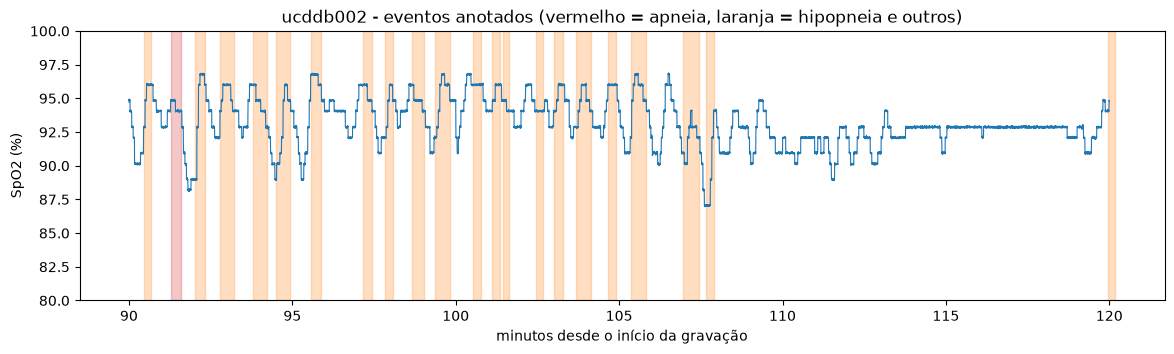

In [14]:
# pedaço de 30 minutos da noite 002 pra ver os eventos em cima do sinal
t0_min, t1_min = 90, 120

# corta o sinal nesse intervalo
x = spo2[int(t0_min * 60 * fs): int(t1_min * 60 * fs)]

# eixo do tempo em minutos
t = t0_min + np.arange(len(x)) / fs / 60

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(t, x, lw=0.8)

# pinta cada evento anotado: vermelho pra apneia, laranja pro resto
for on, dur, typ in zip(ev002["onset_s"], ev002["duration_s"], ev002["type"]):
    if t0_min * 60 <= on <= t1_min * 60:
        ax.axvspan(on / 60, (on + dur) / 60, alpha=0.25, color="tab:red" if typ.startswith("APNEA") else "tab:orange")

ax.set_ylim(80, 100)
ax.set_xlabel("minutos desde o início da gravação")
ax.set_ylabel("SpO2 (%)")
ax.set_title(f"ucddb{SID} - eventos anotados (vermelho = apneia, laranja = hipopneia e outros)")
plt.show()

**Respostas da pergunta 4**
- Batem, usando `(hora do evento - hora do início) mod 24h`. A maioria das gravações passa da meia-noite.
- Conferido: a SpO2 mínima logo depois de cada evento bate com a coluna `Low` (diferença mediana perto de 0).
- A queda da SpO2 aparece depois do evento (tem um atraso), então a janela de busca precisa ir além do fim do evento.

## O que isso muda no `ai/load_ucddb.py`
1. `load_spo2(sid)`: pegar o canal pelo nome `"SpO2"` e devolver o sinal, o `fs` e o horário de início.
2. `load_events(sid)`: ler por largura fixa, aceitar campo vazio, calcular `onset_s` com o mod 24h e filtrar os tipos que entram no rótulo.
3. `load_labels()`: usar `Study Number` e `PSG AHI` pra montar o `osa_ahi15`.